In [1]:
import numpy as np
import torch as tc
import numpy.random as rd
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import argparse
from scipy.integrate import odeint

from circuit_solver import circuit as ct
from circuit_solver import elements as es
from circuit_solver import utils
from circuit_solver.learning import CoupledLearning, SymmetricCoupledLearning, CLTrainingConfig, CLTestingConfig, CoupledLearningEtaZero
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'

In [2]:
def base_params():
    description = ''
    experiment_name = 'voltage divider dynamics'

    # data params
    input_gain = 1.
    output_gain = 1.
    P = 100
    rho = 0.9
    m = 1/3
    seed = 0    # RNG seed for data generation

    # element params
    k1_init = 1.
    k2_init = 1.
    k_min = 0.
    k_max = 1E1
    param_ranges = [(k_min, k_max)]

    # model params
    N = 1
    M = 1

    # training params
    batch_size = P
    N_batches = 1500
    alpha = 0.05

    return argparse.Namespace(**locals())

s = base_params()
eta_values = [0.5, -0.5]

absolute_high = max(s.input_gain, s.output_gain)
s.model_config = ct.CircuitModelConfig(
    HIGH_voltage=absolute_high,
    LOW_voltage=-absolute_high,
)

# Generate data

In [3]:
cov_matrix = np.array([[1, s.m * s.rho],
                        [s.m * s.rho, s.m**2]])
rng = np.random.default_rng(s.seed)
Z = rng.multivariate_normal([0, 0], cov_matrix, size=s.P)
X_data = Z[:, 0][:, None] * s.input_gain
Y_data = Z[:, 1][:, None] * s.output_gain

cov_emp = Z.T @ Z / s.P
cov_emp = cov_emp / cov_emp[0, 0]
m_emp = np.sqrt(cov_emp[1, 1])
rho_emp = cov_emp[0, 1] / m_emp

print(f"m_emp={m_emp:.4f} (true: {s.m:.4f}),  rho_emp={rho_emp:.4f} (true: {s.rho:.4f})")

m_emp=0.3334 (true: 0.3333),  rho_emp=0.9040 (true: 0.9000)


## Functions

In [4]:
def build_model(s, e1, e2):
    N_nodes = 3
    graph = nx.DiGraph()
    graph.add_nodes_from(np.arange(N_nodes))

    x_nodes, y_nodes, GROUND = [0], [1], [2]
    edge_1, edge_2 = (0, 1), (1, 2)
    graph.add_edges_from([edge_1, edge_2])

    circuit = ct.Circuit(graph, {e1: [edge_1], e2: [edge_2]})
    node_type_dict = {
        'GROUND': GROUND, 'HIGH': [], 'LOW': [],
        'x': x_nodes, 'y': y_nodes,
    }
    return ct.CircuitModel(circuit, node_type_dict, s.model_config)


def run_simulation(s, eta, learner=CoupledLearning):
    param_ranges = [(s.k_min, s.k_max)]
    e1 = es.Resistor(name='e1', param_ranges=param_ranges, init_mode='constant', init_params=s.k1_init)
    e2 = es.Resistor(name='e2', param_ranges=param_ranges, init_mode='constant', init_params=s.k2_init)
    model = build_model(s, e1, e2)
    model.set_absorbing()
    training_config = CLTrainingConfig(
        batch_size=s.batch_size,
        N_batches=s.N_batches,
        alpha=s.alpha,
        eta=eta,
    )
    return learner(X_data, Y_data, model, training_config)

In [5]:
print(f"Running simulations for eta = 0 ...")
history_zero = run_simulation(s, 0, learner=CoupledLearningEtaZero)

print(f"Running simulations for eta_values = {eta_values} ...")
histories = {eta: run_simulation(s, eta, learner=CoupledLearning) for eta in eta_values}

eta_sym = 0.5
print(f"Running SymmetricCoupledLearning (eta={eta_sym}) ...")
history_sym = run_simulation(s, eta_sym, learner=SymmetricCoupledLearning)

print("Done.")

Running simulations for eta = 0 ...


100%|██████████| 1500/1500 [00:03<00:00, 395.04it/s]


Running simulations for eta_values = [0.5, -0.5] ...


100%|██████████| 1500/1500 [00:04<00:00, 350.35it/s]


Running SymmetricCoupledLearning (eta=0.5) ...


100%|██████████| 1500/1500 [00:04<00:00, 342.06it/s]

Done.


# Flow plots

In [6]:
def a_func(k1, k2):
    return k1 / (k1 + k2)

def f_eta_0(k, alp, m, rho):
    a = a_func(*k)
    return np.array([
        2 * alp * (a - 1) * (a - m * rho),
        2 * alp * a * (a - m * rho),
    ])

def f_eta_1(k, alp, m, rho):
    a = a_func(*k)
    return np.array([
        alp * (a**2 - m**2 + 2 * (m * rho - a)),
        alp * (a**2 - m**2),
    ])

def f(k, alp, m, rho, eta):
    return (1 - eta) * f_eta_0(k, alp, m, rho) + eta * f_eta_1(k, alp, m, rho)

In [7]:
def plot_flow(ax, history, eta, flow_args, k_max=1.5, ngrid=500, lw=2):
    k1 = history['e1'][0]
    k2 = history['e2'][0]

    x_lim = (0, k_max)
    Xg = np.linspace(*x_lim, ngrid)
    Yg = np.linspace(*x_lim, ngrid)
    kg = np.meshgrid(Xg, Yg)
    dk = f(kg, *flow_args, eta)

    speed = np.sqrt(kg[0]**2 + kg[1]**2)
    ax.streamplot(Xg, Yg, *dk, density=[0.3, 0.4], color=speed, cmap='Greys')

    ax.plot(k1, k2, color='black', linewidth=lw, zorder=3)
    ax.plot(k1[0], k2[0], 'o', color='black', zorder=4, markersize=7)
    ax.plot(k1[-1], k2[-1], 'o', color='black', zorder=4,
            markerfacecolor='white', markersize=7, markeredgewidth=2*lw/3)

    ax.set_xlim(*x_lim)
    ax.set_ylim(*x_lim)
    ax.set_aspect('equal')

# Note on $\eta$ convention

The convention used in the code base (`circuit-solver`) is that positive $\eta$ pushes the outputs towards the desired target state. In the paper, the opposite sign convention is used. This is the reason why the plots below have a mismatch between label and variable definition.

/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_37904/834218011.py:2: RuntimeWarning: invalid value encountered in divide
  return k1 / (k1 + k2)


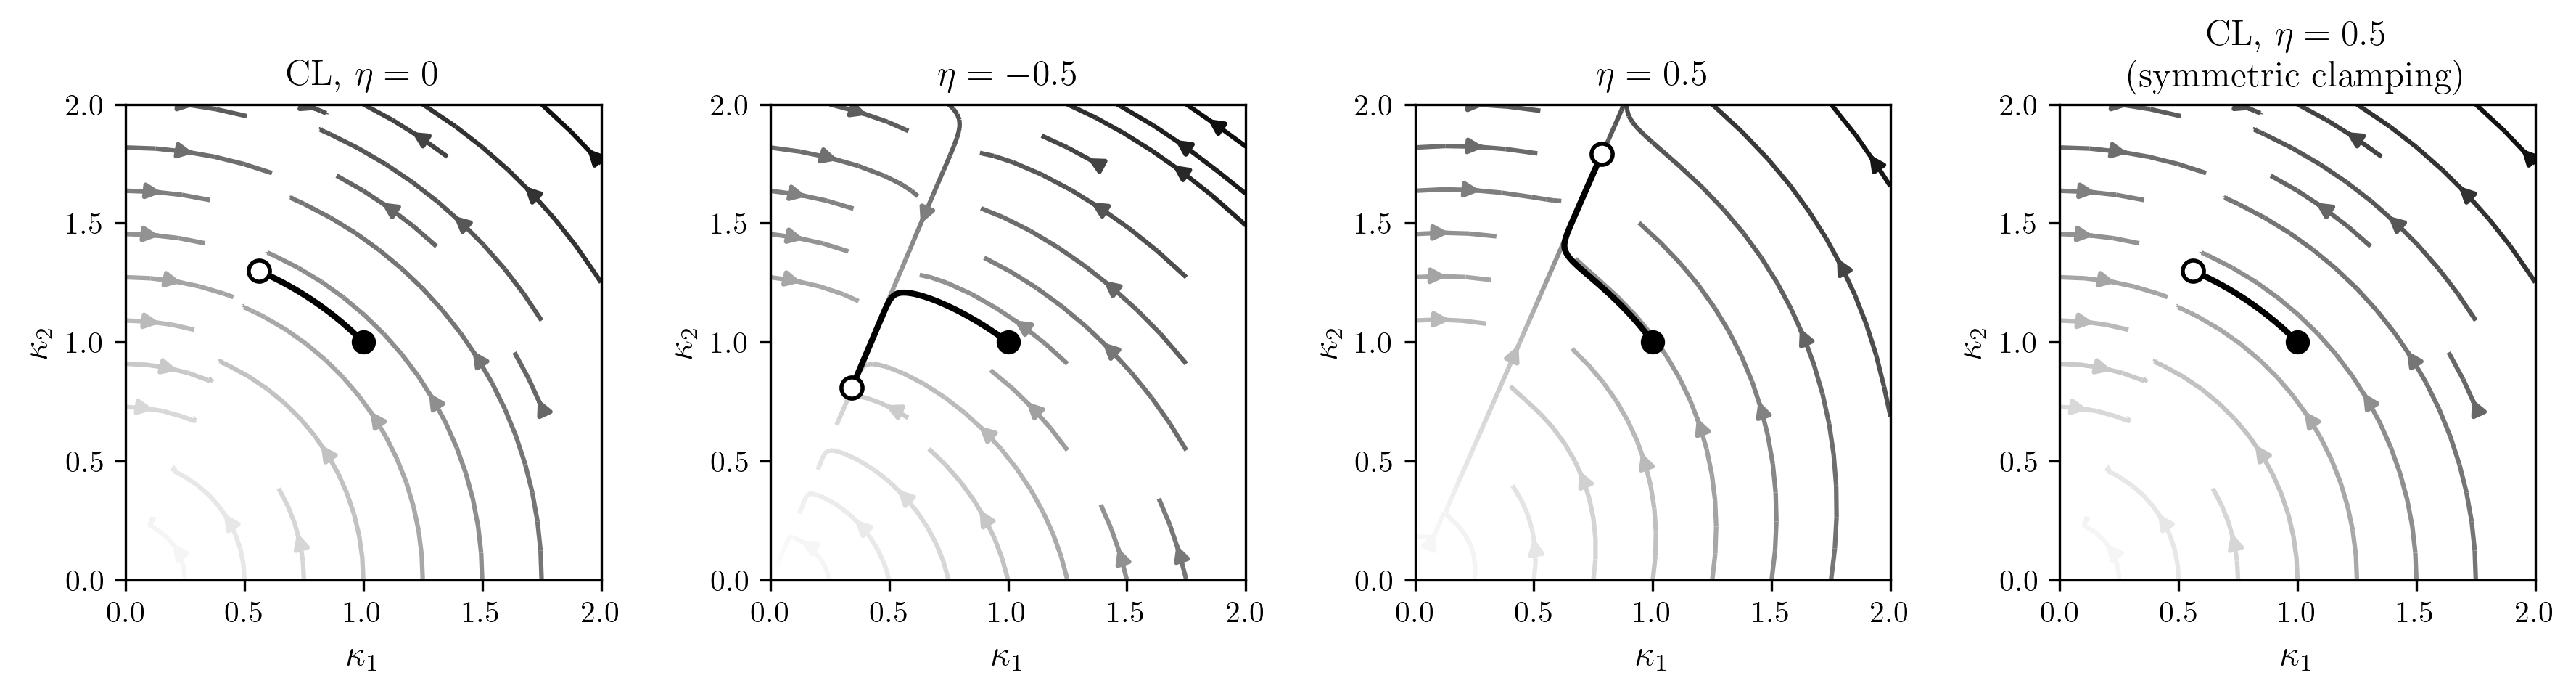

In [8]:
flow_args = (s.alpha, m_emp, rho_emp)
k_max = 2
ticks = np.linspace(0, 2, k_max * 2 + 1)

sz = 3
fs = 12
n_cols = len(eta_values) + 2
fig, axes = plt.subplots(1, n_cols, figsize=(sz * n_cols, sz), dpi=300)

plot_flow(axes[0], history_zero, 0., flow_args, k_max=k_max)
axes[0].set_xticks(ticks)
axes[0].set_yticks(ticks)
axes[0].set_title(f'CL,  $\\eta = 0$', size=fs)

for n, eta in enumerate(eta_values):
    ax = axes[n+1]
    plot_flow(ax, histories[eta], eta, flow_args, k_max=k_max)
    ax.set_title(f'$\\eta = {-eta}$', size=fs)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

# for ax, eta in zip(axes, eta_values):
#     plot_flow(ax, histories[eta], eta, flow_args, k_max=k_max)
#     ax.set_xticks(ticks)
#     ax.set_yticks(ticks)

plot_flow(axes[-1], history_sym, 0., flow_args, k_max=k_max)
axes[-1].set_xticks(ticks)
axes[-1].set_yticks(ticks)
axes[-1].set_title(f'CL,  $\\eta = {eta_sym}$ \n (symmetric clamping)', size=fs)

for ax in axes:
    ax.set_xlabel('$\\kappa_1$', size=fs)
    ax.set_ylabel('$\\kappa_2$', size=fs)

# fig.suptitle('Learning dynamics', y=1.02)
plt.tight_layout()
plt.show()